In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.db import query

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

In [2]:
overview = query("""
SELECT count(*) AS lines,
       count(DISTINCT f.customer_key) AS customers,
       count(DISTINCT f.invoice_no) AS invoices,
       count(DISTINCT f.product_key) AS products,
       MIN(d.full_date) AS first_day,
       MAX(d.full_date) AS last_day,
       SUM(f.line_amount) AS net_revenue
FROM gold.fact_sales f
JOIN gold.dim_date d USING (date_key)
""")
overview.T

,0
lines,797883
customers,5942
invoices,44876
products,4646
first_day,2009-12-01
last_day,2011-12-09
net_revenue,"16,289,439.42"


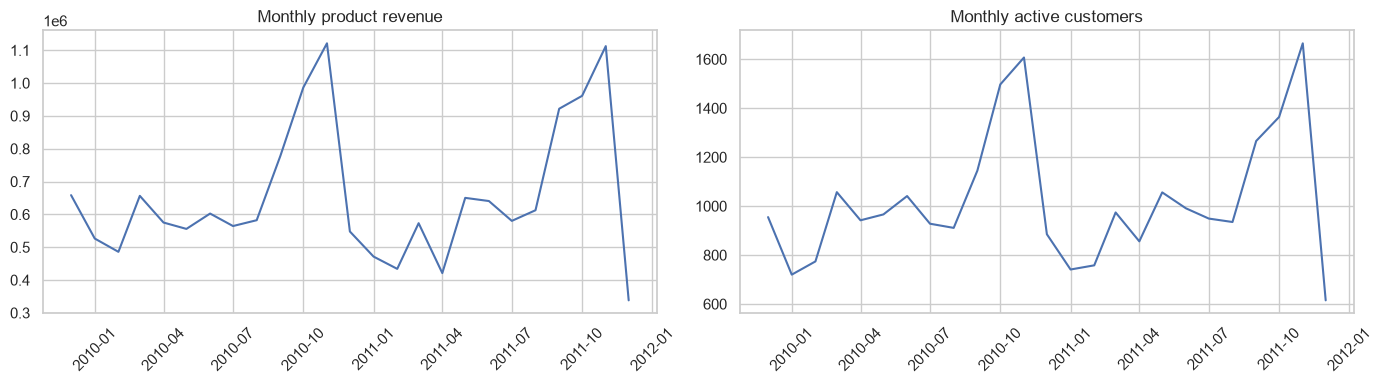

In [3]:
monthly = query("""
SELECT DATE_TRUNC('month', d.full_date)::date AS month,
       SUM(f.line_amount) FILTER (WHERE f.is_product_line) AS revenue,
       COUNT(DISTINCT f.customer_key) FILTER (WHERE NOT f.is_cancellation) AS active_customers
FROM gold.fact_sales f
JOIN gold.dim_date d USING (date_key)
GROUP BY 1 ORDER BY 1
""")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(monthly["month"], monthly["revenue"])
ax[0].set_title("Monthly product revenue")
ax[1].plot(monthly["month"], monthly["active_customers"])
ax[1].set_title("Monthly active customers")
for a in ax:
    a.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

count   5,852.00
mean        6.25
std        12.75
min         1.00
25%         1.00
50%         3.00
75%         7.00
max       373.00
Name: orders, dtype: float64
One-time buyers: 27.6%


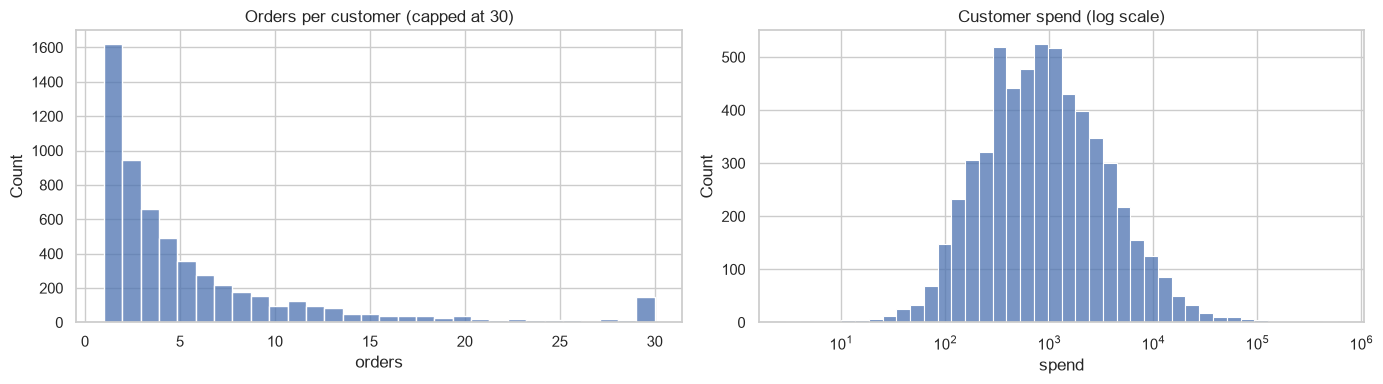

In [4]:
per_customer = query("""
SELECT c.customer_id, c.country,
       COUNT(DISTINCT f.invoice_no) AS orders,
       SUM(f.line_amount) AS spend
FROM gold.fact_sales f
JOIN gold.dim_customer c USING (customer_key)
WHERE NOT f.is_cancellation AND f.is_product_line
  AND f.quantity > 0 AND f.unit_price > 0
GROUP BY 1, 2
""")

print(per_customer["orders"].describe())
print("One-time buyers:", f"{(per_customer['orders'] == 1).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(per_customer["orders"].clip(upper=30), bins=30, ax=ax[0])
ax[0].set_title("Orders per customer (capped at 30)")
sns.histplot(per_customer["spend"].clip(lower=1), log_scale=True, bins=40, ax=ax[1])
ax[1].set_title("Customer spend (log scale)")
plt.tight_layout()
plt.show()

In [5]:
countries = per_customer.groupby("country").agg(
    customers=("customer_id", "count"), revenue=("spend", "sum")
).sort_values("revenue", ascending=False)
countries["revenue_share"] = countries["revenue"] / countries["revenue"].sum()
countries.head(8)

,customers,revenue,revenue_share
country,,,
United Kingdom,5334,"14,288,221.65",0.84
EIRE,3,"586,626.08",0.03
Netherlands,22,"549,773.41",0.03
Germany,106,"383,191.95",0.02
France,93,"309,685.56",0.02
Australia,15,"172,092.14",0.01
Spain,36,"102,122.03",0.01
Switzerland,21,"91,903.94",0.01


## Findings
- 797,883 invoice lines, 5,942 customers, 44,876 invoices, net revenue 16.29M (Dec 2009 to Dec 2011).
- Strong seasonality: revenue and active customers peak in Oct-Nov both years. The final point is a partial month (data ends 9 Dec 2011).
- 27.6% of customers bought only once. Orders per customer are heavily right-skewed; spend is roughly log-normal.
- The UK is 84% of revenue. A few countries have very few customers but large revenue (likely wholesale accounts), so country is a weak feature.
- Implication: churn rates will vary by season, so the model needs multiple snapshot dates and time-based validation.